<!-- d2l:prose id=seqrec-md-1 fw=all -->

# Sequence-Aware Recommender Systems

The interaction matrix records which events occurred but discards their order. That omission matters when recent actions reveal a short-lived intent: a reader comparing cameras may want a memory card next, even if their long-run history concerns books. A sequence-aware recommender instead conditions on an ordered, often timestamped, interaction history [@Quadrana.Cremonesi.Jannach.2018].

Caser [@Tang.Wang.2018] represents the last $L$ items as a matrix and applies two kinds of convolution. Horizontal filters detect local patterns spanning several consecutive items; vertical filters combine the same embedding coordinate across the entire window. The resulting short-term representation is joined with a user embedding that represents longer-term preference.

## Model Architectures

Let $S^u=(S_1^u,\ldots,S_{|S^u|}^u)$ be user $u$'s interactions in chronological order. To score the item at time $t$, Caser embeds the preceding $L$ items as the rows of

$$
\mathbf{E}^{(u, t)} = \begin{bmatrix} \mathbf{q}_{S_{t-L}^u} \\ \vdots \\ \mathbf{q}_{S_{t-2}^u} \\ \mathbf{q}_{S_{t-1}^u} \end{bmatrix},
$$

where $\mathbf{Q}\in\mathbb{R}^{n\times k}$ is the item-embedding matrix and $\mathbf{q}_i$ is its $i$th row. Thus $\mathbf{E}^{(u,t)}\in\mathbb{R}^{L\times k}$ has time along its rows and embedding coordinates along its columns. The image analogy is useful only for specifying the filter shapes; neither axis is spatial.

For horizontal filter $j$, choose a height $h_j\in\{1,\ldots,L\}$ and weights $\mathbf{F}^j\in\mathbb{R}^{h_j\times k}$. The filter scores each consecutive block of $h_j$ items, and max pooling retains its strongest response:

$$
\begin{aligned}
c_{j,s} &= \rho\!\left(\langle\mathbf{F}^j,\mathbf{E}^{(u,t)}_{s:s+h_j-1,:}\rangle+a_j\right),\\
o_j &= \max_s c_{j,s}, \qquad j=1,\ldots,d,
\end{aligned}
$$

Here $\rho$ is an activation function and $\langle\cdot,\cdot\rangle$ is the Frobenius inner product. The $d$ pooled responses form $\mathbf{o}\in\mathbb{R}^d$. A vertical filter $\mathbf{G}^j\in\mathbb{R}^{L\times1}$ instead combines all $L$ time steps separately for each embedding coordinate. Concatenating the outputs of $d'$ such filters gives

$$
\mathbf{o}'=[\rho((\mathbf{E}^{(u,t)})^\top\mathbf{G}^1+a'_1);\ldots;\rho((\mathbf{E}^{(u,t)})^\top\mathbf{G}^{d'}+a'_{d'})]\in\mathbb{R}^{kd'}.
$$

The two branches are concatenated and mapped to a $k$-dimensional representation:

$$
\mathbf{z} = \phi(\mathbf{W}[\mathbf{o};\mathbf{o}'] + \mathbf{b}),
$$

where $\mathbf{W}\in\mathbb{R}^{k\times(d+kd')}$ and $\mathbf{b}\in\mathbb{R}^k$. The vector $\mathbf{z}\in\mathbb{R}^k$ summarizes the recent window.

To retain information beyond the recent window, the final score also includes a user embedding $\mathbf{p}_u\in\mathbb{R}^k$:

$$
\hat{y}_{uit} = \mathbf{v}_i^\top[\mathbf{z};\mathbf{p}_u] + b'_i.
$$

Here $\mathbf{v}_i\in\mathbb{R}^{2k}$ and $b'_i$ are item-specific output parameters. The score can be trained with the BPR loss or a pairwise hinge loss; in either case, the negative items are sampled training comparisons rather than observed dislikes.


![Caser embeds the last $L$ interactions as a matrix. Horizontal filters detect patterns across consecutive items, vertical filters aggregate an embedding coordinate across the window, and a user embedding supplies longer-term information to the item score.](../img/rec-caser.svg)

We first import the required libraries.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
import random

<!-- d2l:prose id=seqrec-md-2 fw=all -->

## Model Implementation
The following code implements the Caser model. It consists of a vertical convolutional layer, a horizontal convolutional layer, and a full-connected layer.

In [3]:
class Caser(nn.Module):
    def __init__(self, num_factors, num_users, num_items, L=5, d=16,
                 d_prime=4, drop_ratio=0.05):
        super().__init__()
        self.P = nn.Embedding(num_users, num_factors)
        self.Q = nn.Embedding(num_items, num_factors)
        self.d_prime, self.d = d_prime, d
        # Vertical convolution layer
        self.conv_v = nn.Conv2d(1, d_prime, (L, 1))
        # Horizontal convolution layer
        h = [i + 1 for i in range(L)]
        self.conv_h = nn.ModuleList(
            [nn.Conv2d(1, d, (i, num_factors)) for i in h])
        self.max_pool = nn.ModuleList(
            [nn.MaxPool1d(L - i + 1) for i in h])
        # Fully connected layer
        self.fc1_dim_v, self.fc1_dim_h = d_prime * num_factors, d * len(h)
        self.fc = nn.Sequential(
            nn.Linear(d_prime * num_factors + d * L, num_factors),
            nn.ReLU())
        self.Q_prime = nn.Embedding(num_items, num_factors * 2)
        self.b = nn.Embedding(num_items, 1)
        self.dropout = nn.Dropout(drop_ratio)

    def forward(self, user_id, seq, item_id):
        item_embs = self.Q(seq).unsqueeze(1)
        user_emb = self.P(user_id)
        out, out_h, out_v, out_hs = None, None, None, []
        if self.d_prime:
            out_v = self.conv_v(item_embs)
            out_v = out_v.reshape(out_v.shape[0], self.fc1_dim_v)
        if self.d:
            for conv, maxp in zip(self.conv_h, self.max_pool):
                conv_out = torch.relu(conv(item_embs)).squeeze(3)
                t = maxp(conv_out)
                pool_out = t.squeeze(2)
                out_hs.append(pool_out)
            out_h = torch.cat(out_hs, dim=1)
        out = torch.cat([out_v, out_h], dim=1)
        z = self.fc(self.dropout(out))
        x = torch.cat([z, user_emb], dim=1)
        # batch_size is 4096 here, so bare squeeze (collapsing all singleton
        # axes) is safe and produces matched shapes for the positive
        # (item_id shape (B,1)) and negative (item_id shape (B,)) paths.
        q_prime_i = self.Q_prime(item_id).squeeze()
        b = self.b(item_id).squeeze()
        res = (x * q_prime_i).sum(1) + b
        return res

<!-- d2l:prose id=seqrec-md-3 fw=all -->

## Sequential Dataset with Negative Sampling
`SeqDataset` converts each user's chronological history into next-item examples. With a window length $L$, an example contains the user identifier, $L$ consecutive items, and the item that followed them. The implementation reserves the final interaction for testing and forms training windows only from earlier events, preventing a future item from entering a training input. It also samples an unobserved item for each positive target to construct the pairwise loss.

As in the NeuMF experiment, the negative pool excludes the known held-out
positive. This avoids a contradictory sampled label but uses the evaluation
event's identity during training; the resulting numbers illustrate the model
and metric rather than a strict untouched-test protocol.

![With nine chronological interactions and $L=5$, the final item is reserved for testing. Sliding a length-five window over the first eight interactions produces three training inputs, each paired with its observed next item and a sampled unobserved item.](../img/rec-seq-data.svg)

In [4]:
class SeqDataset(torch.utils.data.Dataset):
    def __init__(self, user_ids, item_ids, L, num_users, num_items,
                 candidates, test_items=None):
        user_ids = torch.tensor(user_ids, dtype=torch.long)
        item_ids = torch.tensor(item_ids, dtype=torch.long)
        sort_idx = sorted(range(len(user_ids)),
                          key=lambda k: user_ids[k].item())
        sort_idx = torch.tensor(sort_idx, dtype=torch.long)
        u_ids, i_ids = user_ids[sort_idx], item_ids[sort_idx]
        temp, u_ids_np = {}, u_ids.numpy()
        # Precompute each user's negative pool once: items the user has not
        # interacted with in train, excluding the known held-out positive.
        # This is a disclosed protocol shortcut; see the surrounding text.
        all_items = set(range(num_items))
        test_items = test_items or {}
        self.neg_pool = {
            u: list(all_items - set(candidates.get(u, [])) - set(test_items.get(u, [])))
            for u in candidates}
        [temp.setdefault(u_ids_np[i], []).append(i)
         for i, _ in enumerate(u_ids_np)]
        temp = sorted(temp.items(), key=lambda x: x[0])
        u_ids = torch.tensor([i[0] for i in temp], dtype=torch.long)
        idx = torch.tensor([i[1][0] for i in temp], dtype=torch.long)
        self.ns = ns = int(sum([c - L if c >= L + 1 else 1 for c
                                in [len(i[1]) for i in temp]]))
        self.seq_items = torch.zeros(ns, L, dtype=torch.long)
        self.seq_users = torch.zeros(ns, dtype=torch.long)
        self.seq_tgt = torch.zeros(ns, 1, dtype=torch.long)
        self.test_seq = torch.zeros(num_users, L, dtype=torch.long)
        test_users, _uid = torch.empty(num_users), None
        for i, (uid, i_seq) in enumerate(self._seq(u_ids, i_ids, idx, L + 1)):
            if uid != _uid:
                self.test_seq[uid][:] = i_seq[-L:]
                test_users[uid], _uid = uid, uid
            self.seq_tgt[i][:] = i_seq[-1:]
            self.seq_items[i][:], self.seq_users[i] = i_seq[:L], uid

    def _win(self, tensor, window_size, step_size=1):
        if len(tensor) - window_size >= 0:
            for i in range(len(tensor), 0, - step_size):
                if i - window_size >= 0:
                    yield tensor[i - window_size:i]
                else:
                    break
        else:
            yield tensor

    def _seq(self, u_ids, i_ids, idx, max_len):
        for i in range(len(idx)):
            stop_idx = None if i >= len(idx) - 1 else int(idx[i + 1])
            for s in self._win(i_ids[int(idx[i]):stop_idx], max_len):
                yield (int(u_ids[i]), s)

    def __len__(self):
        return self.ns

    def __getitem__(self, idx):
        neg = self.neg_pool[int(self.seq_users[idx])]
        i = random.randint(0, len(neg) - 1)
        return (self.seq_users[idx], self.seq_items[idx], self.seq_tgt[idx],
                neg[i])

<!-- d2l:prose id=seqrec-md-4 fw=all -->

## Load the MovieLens 100K dataset

Afterwards, we read and split the MovieLens 100K dataset in sequence-aware mode and load the training data with sequential dataloader implemented above.

In [5]:
TARGET_NUM, L, batch_size = 1, 5, 4096
df, num_users, num_items = d2l.read_data_ml100k()
train_data, test_data = d2l.split_data_ml100k(df, num_users, num_items,
                                              'seq-aware')
users_train, items_train, ratings_train, candidates = d2l.load_data_ml100k(
    train_data, num_users, num_items, feedback="implicit")
users_test, items_test, ratings_test, test_iter = d2l.load_data_ml100k(
    test_data, num_users, num_items, feedback="implicit")
train_seq_data = SeqDataset(users_train, items_train, L, num_users,
                            num_items, candidates, test_items=test_iter)
train_iter = torch.utils.data.DataLoader(train_seq_data, batch_size,
                                         shuffle=True, drop_last=True,
                                         num_workers=d2l.get_dataloader_workers())
test_seq_iter = train_seq_data.test_seq
train_seq_data[0]

(tensor(0), tensor([241, 170, 110, 255,   4]), tensor([101]), 809)

<!-- d2l:prose id=seqrec-md-5 fw=all -->

The training data structure is shown above. The first element is the user identity, the second is the list of the last five items this user liked, the third is the target item this user liked after those five, and the fourth is a randomly sampled negative item.

## Train the Model
Now, let's train the model. We use the same setting as NeuMF, including learning rate, optimizer, and $k$, in the last section so that the results are comparable.

train loss 0.130, test hit rate 0.382, test AUC 0.886
748.4 examples/sec on [device(type='cuda', index=0)]


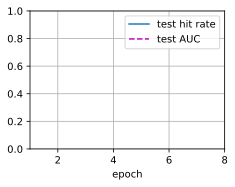

In [6]:
devices = d2l.try_all_gpus()
net = Caser(10, num_users, num_items, L)
def _init(m):
    # Match MX's `init.Normal(0.01)` semantics: initialize weights *and*
    # biases, so biases don't keep their default uniform fan-in init.
    if hasattr(m, 'weight') and m.weight is not None:
        nn.init.normal_(m.weight, 0, 0.01)
    if hasattr(m, 'bias') and m.bias is not None:
        nn.init.zeros_(m.bias)
net.apply(_init)
net = net.to(devices[0])
lr, num_epochs, wd, optimizer = 0.04, 8, 1e-5, 'adam'
loss = d2l.BPRLoss()
trainer = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=wd)

# `evaluate_ranking` is the bottleneck — it scores every (user, item)
# pair that the user has not interacted with, so per-epoch evaluation
# dominates total runtime. Setting `eval_step=num_epochs` defers
# evaluation to the final epoch only, which keeps the cell well under
# an hour while still reporting hit-rate / AUC for the trained model.
d2l.train_ranking(net, train_iter, test_iter, loss, trainer,
                  test_seq_iter, num_users, num_items, num_epochs,
                  devices, d2l.evaluate_ranking, candidates,
                  eval_step=num_epochs)

<!-- d2l:prose id=seqrec-md-6 fw=all -->

## Summary
* Sequence-aware recommendation predicts the next item from an ordered interaction history rather than an unordered user--item matrix.
* Caser combines convolutional features of the recent window with a user embedding for longer-term preference.

## Exercises

1. Session-based recommendation [@Hidasi.Karatzoglou.Baltrunas.ea.2015]
   predicts the next item within an anonymous browsing session, without a
   user identifier. List the inputs of Caser that are unavailable in this
   setting, state what the score $\hat y_{uit}$ reduces to without
   $\mathbf p_u$, and describe a train/test split for session data that plays
   the role of the `seq-aware` mode.
1. Show that the vertical branch with one filter and the identity activation
   computes a weighted sum of the $L$ item embeddings, and that with equal
   filter weights it does not depend on the order of the window at all. To
   which reorderings of the window is the output of one horizontal filter of
   height 1 invariant? Then shuffle the $L$ items of every row of
   `test_seq_iter` and evaluate the trained model again. How much of its hit
   rate and AUC depends on the order within the window?
1. A first-order Markov baseline scores candidate $j$ for user $u$ by the
   number of times $j$ immediately follows $u$'s most recent training item in
   the chronological training sequences of all users. Implement it, evaluate
   it with `evaluate_ranking`, and compare its hit rate and AUC with those of
   Caser and of a ranking by item popularity.
1. Remove the horizontal branch, and separately the vertical branch. The
   input size of the fully connected layer must follow the active branches;
   the code as written fails with `d=0` or `d_prime=0`. Report the hit rate
   and AUC of the full model and of the two ablations. Is the difference
   between them larger than the change you observe when you retrain the full
   model with a different random seed?
1. Train Caser with $L\in\{1, 3, 5, 10\}$. With $L=1$ the window holds only
   the previous item, so the model is a first-order Markov model plus a user
   embedding. Report the hit rate, the AUC, and the number of training
   windows `len(train_seq_data)` for each $L$, and explain why a change in
   accuracy with $L$ cannot be attributed to the history length alone.

<!-- d2l:prose id=seqrec-md-7 fw=pytorch -->

[Discussions](https://d2l.discourse.group/t/404)